Nạp cấu hình và dữ liệu đã gán nhãn

In [1]:
import os, sys, json, re, subprocess
from pathlib import Path
import numpy as np
import pandas as pd

# Jupyter Lab chạy kernel với thư mục hiện hành = thư mục chứa notebook (ics-ai/notebooks)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
# Phải trùng với WORK_DIR 
WORK_DIR = Path(os.environ.get('CIC_MODBUS_WORK', PROJECT_ROOT / 'Modbus-Work')).resolve()
CFG = json.loads((WORK_DIR / 'config.json').read_text(encoding='utf-8'))
DATA_ROOT = Path(CFG['data_root'])
SCENARIOS = list(CFG['capture_points'].keys())
ATTACK_SCENARIOS = [s for s in SCENARIOS if s != 'benign']
print('DATA_ROOT :', DATA_ROOT)
print('WORK_DIR  :', WORK_DIR)
print('Kịch bản  :', SCENARIOS)

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def natural_key(p):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', Path(p).name)]

CLASS_MAP = json.loads((WORK_DIR / 'class_map.json').read_text(encoding='utf-8'))
CLASSES = CLASS_MAP['classes']
print('Các lớp:', CLASSES)

DATA_ROOT : C:\Users\cvson\Documents\Project\Anomaly-detection-in-ICS\ics-ai\Modbus-Dataset
WORK_DIR  : C:\Users\cvson\Documents\Project\Anomaly-detection-in-ICS\ics-ai\Modbus-Work
Kịch bản  : ['benign', 'external', 'compromised_scada', 'compromised_ied']
Các lớp: ['Normal', 'Brute force', 'Query flooding', 'Replay', 'Frame stacking', 'Payload injection', 'Recon', 'FDI', 'Length manipulation']


In [2]:
PREFER_PAYLOAD_BYTES = True
SPLIT_MODE = 'random'      # 'random' (như bài báo) hoặc 'temporal'
SEED = 42
OUT = WORK_DIR / 'processed'
OUT.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(WORK_DIR / 'manifest.csv')
COLS = ['time', 'ip_src', 'ip_dst', 'ip_hdr_len', 'ip_dsfield', 'ip_len', 'ip_id', 'ip_flags', 'ip_frag_offset',
        'ip_ttl', 'ip_proto', 'tcp_srcport', 'tcp_dstport', 'tcp_hdr_len', 'tcp_flags', 'tcp_window',
        'mb_trans_id', 'mb_prot_id', 'mb_len', 'mb_unit_id', 'func_code', 'n_pdus', 'payload_len', 'payload_hex12',
        'scenario', 'file_id', 'label', 'label_id', 'in_delay_window']
labeled_files = [WORK_DIR / 'labeled' / r.scenario / (Path(r.file).stem + '.parquet') for r in manifest.itertuples()]
labeled_files = [f for f in labeled_files if f.exists()]
print(len(labeled_files), 'file đã gán nhãn')

58 file đã gán nhãn


Tái tạo lại dạng byte

In [3]:
def hi(x): return ((x >> 8) & 0xFF).astype(np.uint8)
def lo(x): return (x & 0xFF).astype(np.uint8)

def normalize_ip_flags(v):
    """tshark 4.x trả ip.flags là 3 bit (0x02 = DF). Một số phiên bản cũ trả dạng đã dịch (0x40 hoặc 0x4000)."""
    v = v.copy()
    v = np.where(v > 0xFF, v >> 13, np.where(v > 0x07, v >> 5, v))
    return v & 0x7

def reconstruct(df: pd.DataFrame):
    n = len(df)
    g = {c: df[c].to_numpy().astype(np.int64) for c in COLS
         if c not in ('ip_src', 'ip_dst', 'payload_hex12', 'scenario', 'file_id', 'label', 'in_delay_window', 'time')}
    missing = {c: int((g[c] < 0).sum()) for c in g if (g[c] < 0).any()}
    for c in g:
        g[c] = np.where(g[c] < 0, 0, g[c])
    B = np.zeros((n, 30), np.uint8)
    # ---- IPv4: byte 0-9 ----
    B[:, 0] = (4 << 4) | ((g['ip_hdr_len'] // 4) & 0x0F)
    B[:, 1] = lo(g['ip_dsfield'])
    B[:, 2], B[:, 3] = hi(g['ip_len']), lo(g['ip_len'])
    B[:, 4], B[:, 5] = hi(g['ip_id']), lo(g['ip_id'])
    fo = g['ip_frag_offset']
    if (fo > 0).any() and (fo[fo > 0] % 8 == 0).all():   # một số phiên bản tshark hiển thị offset theo byte
        fo = fo // 8
    ff = (normalize_ip_flags(g['ip_flags']) << 13) | (fo & 0x1FFF)
    B[:, 6], B[:, 7] = hi(ff), lo(ff)
    B[:, 8] = lo(g['ip_ttl'])
    B[:, 9] = lo(g['ip_proto'])
    # ---- TCP: byte 10-17 ----
    B[:, 10], B[:, 11] = hi(g['tcp_srcport']), lo(g['tcp_srcport'])
    B[:, 12], B[:, 13] = hi(g['tcp_dstport']), lo(g['tcp_dstport'])
    tf = g['tcp_flags']
    B[:, 14] = (((g['tcp_hdr_len'] // 4) & 0x0F) << 4) | ((tf >> 8) & 0x0F)
    B[:, 15] = lo(tf)
    B[:, 16], B[:, 17] = hi(g['tcp_window']), lo(g['tcp_window'])
    # ---- MBAP + FC: byte 18-25 (từ trường tshark, như bài báo) ----
    B[:, 18], B[:, 19] = hi(g['mb_trans_id']), lo(g['mb_trans_id'])
    B[:, 20], B[:, 21] = hi(g['mb_prot_id']), lo(g['mb_prot_id'])
    B[:, 22], B[:, 23] = hi(g['mb_len']), lo(g['mb_len'])
    B[:, 24] = lo(g['mb_unit_id'])
    B[:, 25] = lo(g['func_code'])
    # ---- byte thô 12 byte đầu của TCP payload ----
    hexs = df['payload_hex12'].fillna('').str.ljust(24, '0').str[:24]
    raw = np.frombuffer(bytes.fromhex(''.join(hexs.tolist())), np.uint8).reshape(n, 12) if n else np.zeros((0, 12), np.uint8)
    have = df['payload_len'].to_numpy() >= 8
    mismatch = have & (B[:, 18:26] != raw[:, 0:8]).any(axis=1)
    if PREFER_PAYLOAD_BYTES:
        B[mismatch, 18:26] = raw[mismatch, 0:8]
    # ---- PDU operands: byte 26-29 ----
    B[:, 26:30] = raw[:, 8:12]
    plen = df['payload_len'].to_numpy()
    for k in range(4):                    # payload ngắn hơn 8+k byte -> byte đó = 0
        B[plen < 9 + k, 26 + k] = 0
    stats = dict(n=n, mbap_field_vs_payload_mismatch=int(mismatch.sum()), **{f'missing_{k}': v for k, v in missing.items()})
    return B, stats

bytes_parts, meta_parts, stats_rows = [], [], []
for f in tqdm(labeled_files, desc='Tái tạo byte'):
    df = pd.read_parquet(f, columns=COLS)
    if not len(df):
        continue
    B, st = reconstruct(df)
    bytes_parts.append(B)
    meta_parts.append(df[['time', 'scenario', 'file_id', 'ip_src', 'ip_dst', 'func_code', 'n_pdus',
                          'label', 'label_id', 'in_delay_window']].astype({'ip_src': str, 'ip_dst': str}))
    stats_rows.append(dict(file=f.name, **st))
BYTES = np.concatenate(bytes_parts); del bytes_parts
META = pd.concat(meta_parts, ignore_index=True); del meta_parts
for c in ['scenario', 'file_id', 'ip_src', 'ip_dst']:
    META[c] = META[c].astype('category')
META['label'] = pd.Categorical(META['label'].astype(str), categories=CLASSES)
print('BYTES:', BYTES.shape, BYTES.dtype, f'{BYTES.nbytes / 1e6:.0f} MB')
pd.DataFrame(stats_rows).fillna(0).sum(numeric_only=True).astype(int)

Tái tạo byte:   0%|          | 0/58 [00:00<?, ?it/s]

BYTES: (11390143, 30) uint8 342 MB


n                                 11390143
mbap_field_vs_payload_mismatch      138814
dtype: int64

Kiểm chứng việc tái tạo lại byte

In [4]:
chk = {}
chk['byte0 == 0x45 (IPv4, IHL=5)'] = float((BYTES[:, 0] == 0x45).mean())
chk['byte9 == 6 (TCP)'] = float((BYTES[:, 9] == 6).mean())
chk['port 502 ở src hoặc dst'] = float((((BYTES[:, 10].astype(int) << 8 | BYTES[:, 11]) == 502) |
                                        ((BYTES[:, 12].astype(int) << 8 | BYTES[:, 13]) == 502)).mean())
chk['MBAP protocol id == 0'] = float(((BYTES[:, 20] == 0) & (BYTES[:, 21] == 0)).mean())
for k, v in chk.items():
    print(f'{k:35s} {100 * v:8.4f} %')

# Kiểm tra tràn bit trên các trường gốc (lấy mẫu tối đa 2 triệu dòng cho nhanh)
LIMITS = {'ip_hdr_len': 60, 'ip_dsfield': 255, 'ip_len': 65535, 'ip_id': 65535, 'ip_ttl': 255, 'ip_proto': 255,
          'tcp_srcport': 65535, 'tcp_dstport': 65535, 'tcp_hdr_len': 60, 'tcp_flags': 0xFFF, 'tcp_window': 65535,
          'mb_trans_id': 65535, 'mb_prot_id': 65535, 'mb_len': 65535, 'mb_unit_id': 255, 'func_code': 255}
over = {}
for f in labeled_files[:min(len(labeled_files), 10)]:
    d = pd.read_parquet(f, columns=list(LIMITS))
    for c, lim in LIMITS.items():
        over[c] = over.get(c, 0) + int((d[c] > lim).sum())
print('\nSố giá trị vượt độ rộng bit (phải bằng 0):', {k: v for k, v in over.items() if v} or 'không có')

byte0 == 0x45 (IPv4, IHL=5)         100.0000 %
byte9 == 6 (TCP)                    100.0000 %
port 502 ở src hoặc dst             100.0000 %
MBAP protocol id == 0               100.0000 %

Số giá trị vượt độ rộng bit (phải bằng 0): không có


So với byte thô trực tiếp từ pcap

In [5]:
try:
    import dpkt
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dpkt'], check=True)
    import dpkt
import socket

def raw_bytes_from_pcap(path, max_pkts=200_000):
    rows, keys = [], []
    with open(path, 'rb') as fh:
        try:
            rd = dpkt.pcap.Reader(fh)
        except ValueError:
            fh.seek(0); rd = dpkt.pcapng.Reader(fh)
        for ts, buf in rd:
            try:
                eth = dpkt.ethernet.Ethernet(buf)
            except Exception:
                continue
            ip = eth.data
            if not isinstance(ip, dpkt.ip.IP) or not isinstance(ip.data, dpkt.tcp.TCP):
                continue
            tcp = ip.data
            if not tcp.data or 502 not in (tcp.sport, tcp.dport):
                continue
            iph = bytes(ip)[:ip.hl * 4]; tcph = bytes(tcp)[:tcp.off * 4]
            b = iph[0:10] + tcph[0:4] + tcph[12:16] + (tcp.data[:12] + b'\x00' * 12)[:12]
            rows.append(np.frombuffer(b, np.uint8)); keys.append((int(round(ts * 1e6)), ip.id, tcp.sport, tcp.dport))
            if len(rows) >= max_pkts:
                break
    return np.array(rows), pd.DataFrame(keys, columns=['t', 'ip_id', 'sport', 'dport'])

done = {f.stem for f in labeled_files}
r0 = manifest[manifest.file.str.replace('.pcap', '', regex=False).isin(done)]
pick = r0[r0.scenario != 'benign'].iloc[0] if (r0.scenario != 'benign').any() else r0.iloc[0]
pcap_path = DATA_ROOT / pick.rel_path
print('So khớp với:', pcap_path.name)
RAW, K = raw_bytes_from_pcap(pcap_path)

sel = (META.file_id == pick.file_id).to_numpy()
mine = BYTES[sel]
lab = pd.read_parquet(WORK_DIR / 'labeled' / pick.scenario / (Path(pick.file).stem + '.parquet'),
                      columns=['time', 'ip_id', 'tcp_srcport', 'tcp_dstport', 'payload_len'])
lab['t'] = (lab.time * 1e6).round().astype(np.int64)    # khoá theo micro-giây (pcap lưu µs)
# Payload ngắn: dpkt đệm 0 cho tới 12 byte; reconstruct() cũng vậy, nên so sánh được.
# Gói trùng khoá (ví dụ bản sao replay giống hệt) được bỏ khỏi phép so sánh
dup_raw = K.duplicated(keep=False).to_numpy()
key_raw = pd.MultiIndex.from_frame(K[~dup_raw])
RAWu = RAW[~dup_raw]
key_mine = pd.MultiIndex.from_frame(lab[['t', 'ip_id', 'tcp_srcport', 'tcp_dstport']])
pos = key_raw.get_indexer(key_mine)
ok = pos >= 0
print(f'Ghép được {ok.sum():,}/{len(lab):,} gói (dpkt đọc tối đa 200.000 gói đầu)')
agree = (mine[ok] == RAWu[pos[ok]]).mean(axis=0)
pd.DataFrame({'byte': range(30), 'khớp_%': (100 * agree).round(4)}).set_index('byte').T

So khớp với: network-wide-normal-0.pcap
Ghép được 200,000/208,011 gói (dpkt đọc tối đa 200.000 gói đầu)


byte,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
khớp_%,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


Chuyển sang dạng ảnh nhị phân

In [6]:
APPROACHES = {
    '1':  dict(layers='TCP/IP only',             bytes=(0, 18),  shape=(12, 12)),
    '2':  dict(layers='TCP/IP + MBAP + FC',       bytes=(0, 26),  shape=(16, 13)),
    '2b': dict(layers='TCP/IP + MBAP + FC + PDU', bytes=(0, 30),  shape=(16, 15)),
    '3':  dict(layers='App layer only',           bytes=(18, 26), shape=(8, 8)),
    '3b': dict(layers='App layer + PDU',          bytes=(18, 30), shape=(12, 8)),
}
for k, a in APPROACHES.items():
    nb = a['bytes'][1] - a['bytes'][0]
    assert nb * 8 == a['shape'][0] * a['shape'][1], k

def to_images(bytes30: np.ndarray, approach: str) -> np.ndarray:
    """(N, 30) uint8 -> (N, H, W) uint8 với giá trị 0/1."""
    a = APPROACHES[approach]
    s, e = a['bytes']
    bits = np.unpackbits(bytes30[:, s:e], axis=1)
    return bits.reshape(-1, *a['shape'])

pd.DataFrame(APPROACHES).T

,layers,bytes,shape
1,TCP/IP only,"(0, 18)","(12, 12)"
2,TCP/IP + MBAP + FC,"(0, 26)","(16, 13)"
2b,TCP/IP + MBAP + FC + PDU,"(0, 30)","(16, 15)"
3,App layer only,"(18, 26)","(8, 8)"
3b,App layer + PDU,"(18, 30)","(12, 8)"


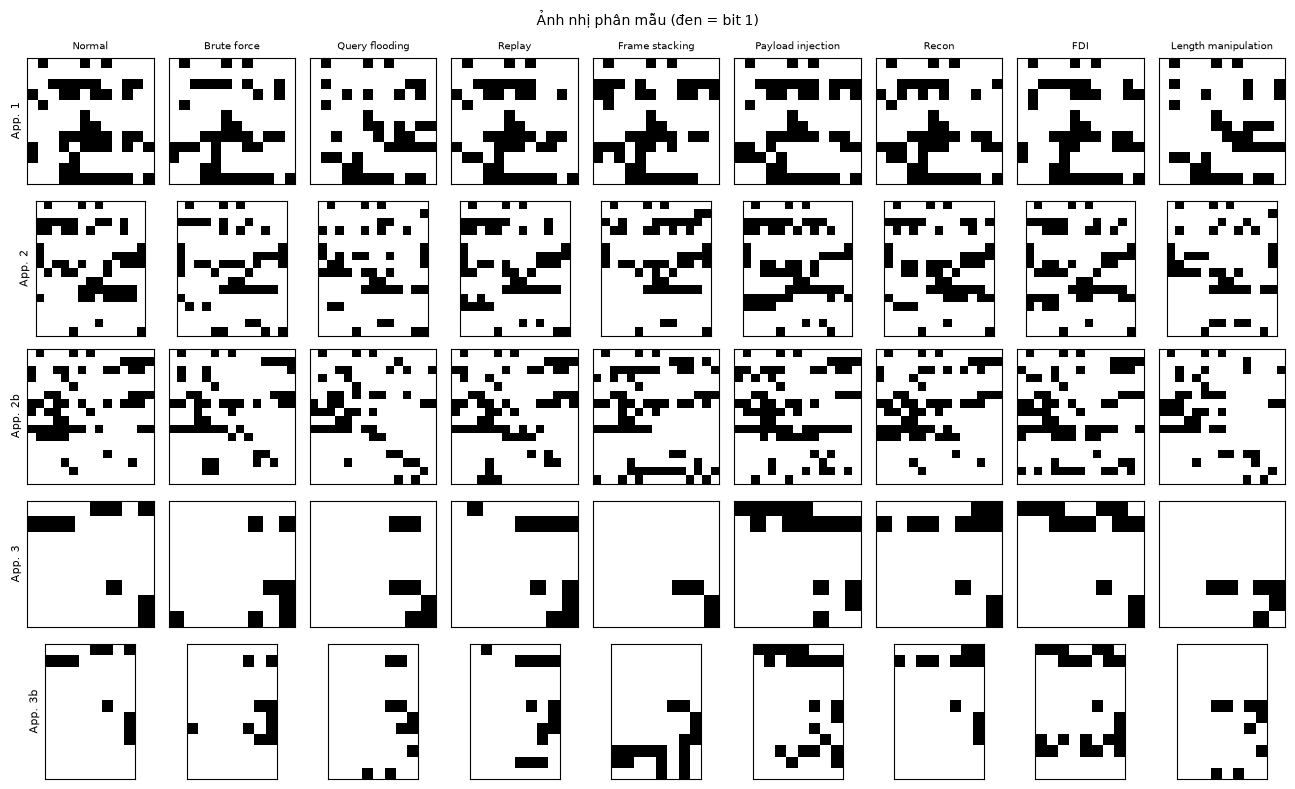

In [7]:
rng = np.random.default_rng(SEED)
present = [c for c in CLASSES if (META.label == c).any()]
sample_idx = {c: rng.choice(np.flatnonzero((META.label == c).to_numpy())) for c in present}
fig, axes = plt.subplots(len(APPROACHES), len(present), figsize=(1.45 * len(present), 1.6 * len(APPROACHES)), squeeze=False)
for i, ap in enumerate(APPROACHES):
    for j, c in enumerate(present):
        img = to_images(BYTES[[sample_idx[c]]], ap)[0]
        ax = axes[i, j]
        ax.imshow(1 - img, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(c, fontsize=7)
        if j == 0: ax.set_ylabel(f'App. {ap}', fontsize=8)
plt.suptitle('Ảnh nhị phân mẫu (đen = bit 1)', fontsize=10)
plt.tight_layout(); plt.show()

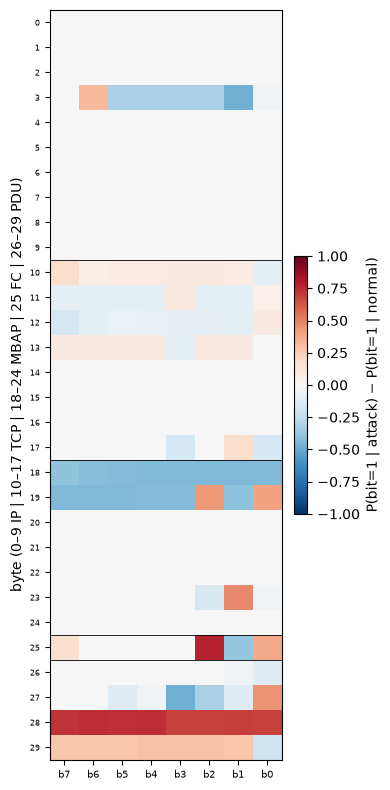

In [8]:
lbl = META.label_id.to_numpy()
take = lambda m, k=300_000: np.flatnonzero(m)[:k] if m.sum() <= k else rng.choice(np.flatnonzero(m), k, replace=False)
if (lbl > 0).any():
    bits = lambda idx: np.unpackbits(BYTES[idx], axis=1).mean(axis=0)
    diff = (bits(take(lbl > 0)) - bits(take(lbl == 0))).reshape(30, 8)
    fig, ax = plt.subplots(figsize=(4, 8))
    im = ax.imshow(diff, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_yticks(range(30)); ax.set_yticklabels([f'{b}' for b in range(30)], fontsize=6)
    ax.set_xticks(range(8)); ax.set_xticklabels([f'b{7 - i}' for i in range(8)], fontsize=7)
    for y in [9.5, 17.5, 24.5, 25.5]:
        ax.axhline(y, color='k', lw=0.6)
    ax.set_ylabel('byte (0–9 IP | 10–17 TCP | 18–24 MBAP | 25 FC | 26–29 PDU)')
    plt.colorbar(im, ax=ax, fraction=0.05, label='P(bit=1 | attack) − P(bit=1 | normal)')
    plt.tight_layout(); plt.show()

Chia dữ liệu Train/Validate/Test (80/10/10)

In [9]:
def percent_rank_split(meta: pd.DataFrame, mode='random', seed=SEED):
    rng = np.random.default_rng(seed)
    split = np.empty(len(meta), dtype=object)
    for c, idx in meta.groupby('label', observed=True).indices.items():
        if mode == 'random':
            order = rng.permutation(len(idx))
        elif mode == 'temporal':
            order = np.argsort(np.argsort(meta.time.to_numpy()[idx], kind='stable'), kind='stable')
        else:
            raise ValueError(mode)
        pr = order / len(idx)                       # thứ hạng phần trăm trong lớp, thuộc [0, 1)
        split[idx] = np.where(pr < 0.8, 'train', np.where(pr < 0.9, 'val', 'test'))
    return pd.Categorical(split, categories=['train', 'val', 'test'])

META['split'] = percent_rank_split(META, SPLIT_MODE)
tab = META.groupby(['label', 'split'], observed=False).size().unstack('split')
tab['% total'] = (100 * tab.sum(axis=1) / len(META)).round(3)
PAPER_T3 = {'Normal': (8_597_652, 1_074_707, 1_074_707), 'Brute force': (505_960, 63_245, 63_245),
            'Query flooding': (4_773, 597, 597), 'Replay': (1_425, 178, 179), 'Frame stacking': (1_068, 133, 134),
            'Payload injection': (290, 36, 37), 'Recon': (284, 35, 36), 'FDI': (42, 5, 6), 'Length manipulation': (20, 3, 3)}
tab['paper (train/val/test)'] = tab.index.map(lambda c: '/'.join(f'{x:,}' for x in PAPER_T3.get(c, ())))
print(f'SPLIT_MODE = {SPLIT_MODE!r}')
tab

SPLIT_MODE = 'random'


split,train,val,test,% total,paper (train/val/test)
label,,,,,
Normal,8552596,1069075,1069074,93.860,"8,597,652/1,074,707/1,074,707"
Brute force,542053,67757,67756,5.949,"505,960/63,245/63,245"
Query flooding,8736,1092,1092,0.096,"4,773/597/597"
Replay,3775,472,471,0.041,"1,425/178/179"
Frame stacking,1157,145,144,0.013,"1,068/133/134"
Payload injection,1750,219,218,0.019,290/36/37
Recon,1601,200,200,0.018,284/35/36
FDI,43,5,5,0.000,42/5/6
Length manipulation,406,51,50,0.004,20/3/3


Lưu kết quả

In [10]:
np.save(OUT / 'bytes30.npy', BYTES)
np.save(OUT / 'labels.npy', META.label_id.to_numpy().astype(np.int8))
META.to_parquet(OUT / 'meta.parquet', index=False)
(OUT / 'approaches.json').write_text(json.dumps(APPROACHES, indent=2), encoding='utf-8')
(OUT / 'class_map.json').write_text(json.dumps(dict(classes=CLASSES, binary={'0': 'Normal', '1': 'Attack'},
                                    split_mode=SPLIT_MODE, seed=SEED, prefer_payload_bytes=PREFER_PAYLOAD_BYTES,
                                    labelling_params=CLASS_MAP.get('labelling_params')), indent=2, ensure_ascii=False), encoding='utf-8')
for f in sorted(OUT.iterdir()):
    print(f'{f.name:20s} {f.stat().st_size / 1e6:10.1f} MB')

approaches.json             0.0 MB
bytes30.npy               341.7 MB
class_map.json              0.0 MB
labels.npy                 11.4 MB
meta.parquet               72.1 MB


Kiểm tra nhanh: Nạp lại và tạo một batch

In [11]:
B_ = np.load(OUT / 'bytes30.npy', mmap_mode='r')
Y_ = np.load(OUT / 'labels.npy')
M_ = pd.read_parquet(OUT / 'meta.parquet', columns=['split'])
CAP = 5_000
tr = np.flatnonzero((M_.split == 'train').to_numpy())
rng = np.random.default_rng(SEED)
capped = np.concatenate([rng.permutation(tr[Y_[tr] == c])[:CAP] for c in np.unique(Y_[tr])])
Xb = to_images(np.asarray(B_[np.sort(capped)]), '2b')
yb = Y_[np.sort(capped)]
N, K = len(yb), len(np.unique(yb))
w = {CLASSES[c]: round(N / (K * (yb == c).sum()), 3) for c in np.unique(yb)}
print('Batch train (cap=5000/lớp):', Xb.shape, Xb.dtype, '| giá trị:', np.unique(Xb))
print('Trọng số lớp N/(K·N_c):', w)

Batch train (cap=5000/lớp): (23732, 16, 15) uint8 | giá trị: [0 1]
Trọng số lớp N/(K·N_c): {'Normal': np.float64(0.527), 'Brute force': np.float64(0.527), 'Query flooding': np.float64(0.527), 'Replay': np.float64(0.699), 'Frame stacking': np.float64(2.279), 'Payload injection': np.float64(1.507), 'Recon': np.float64(1.647), 'FDI': np.float64(61.323), 'Length manipulation': np.float64(6.495)}
